# RT01 - Fastest routes on a real street network

Question: how do we compute fastest routes on a real street network?

Graph: OpenStreetMap drive network of Manhattan, fetched with `osmnx` and cached
to GraphML. Weight: edge `length` in metres.

Methods: Dijkstra, and A* with a haversine heuristic (straight-line distance to the goal).

In [1]:
import os
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from shapely.geometry import LineString

from routes_pricing.graph import load_drive_graph
from street_routing.nodes import nearest_node
from street_routing.search import astar, dijkstra, path_length

DATA_DIR = Path(os.environ.get("UBER_DATA_DIR", "../data")).expanduser()
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
PLACE = "Manhattan, New York City, New York, USA"
RANDOM_STATE = 42

## 1. Load the cached street graph

In [2]:
G = load_drive_graph(PLACE, DATA_DIR / "cache" / "manhattan_drive.graphml")
print(f"nodes={G.number_of_nodes():,}  edges={G.number_of_edges():,}")

nodes=4,635  edges=9,918


## 2. Route between landmarks and compare with networkx

In [3]:
pairs = {
    "Times Square -> Grand Central": ((40.7580, -73.9855), (40.7527, -73.9772)),
    "Battery Park -> Columbus Circle": ((40.7033, -74.0170), (40.7681, -73.9819)),
    "Washington Sq -> Harlem 125th": ((40.7308, -73.9973), (40.8150, -73.9493)),
}

rows = []
for name, (src_ll, dst_ll) in pairs.items():
    s, t = nearest_node(G, *src_ll), nearest_node(G, *dst_ll)
    t0 = time.perf_counter()
    d_path, d_cost, d_exp = dijkstra(G, s, t)
    d_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    a_path, a_cost, a_exp = astar(G, s, t)
    a_time = time.perf_counter() - t0
    nx_cost = nx.dijkstra_path_length(G, s, t, weight="length")
    rows.append({
        "route": name,
        "dijkstra_m": round(d_cost), "astar_m": round(a_cost), "networkx_m": round(nx_cost),
        "dijkstra_expanded": d_exp, "astar_expanded": a_exp,
        "dijkstra_ms": round(d_time * 1000, 1), "astar_ms": round(a_time * 1000, 1),
        "path_nodes": len(a_path), "_a_path": a_path,
    })

import pandas as pd
summary = pd.DataFrame(rows).drop(columns="_a_path")
summary

,route,dijkstra_m,astar_m,networkx_m,dijkstra_expanded,astar_expanded,dijkstra_ms,astar_ms,path_nodes
0,Times Square -> Grand Central,1437,1437,1437,232,44,1.7,1.3,15
1,Battery Park -> Columbus Circle,8011,8011,8011,2129,525,15.0,15.5,106
2,Washington Sq -> Harlem 125th,10835,10835,10835,3547,404,31.7,14.0,131


Dijkstra, A*, and networkx must agree on the optimal length. The expansion counts
show how much of the graph A* avoids exploring.

In [4]:
assert np.allclose(summary["dijkstra_m"], summary["networkx_m"])
assert np.allclose(summary["astar_m"], summary["networkx_m"])
assert (summary["astar_expanded"] <= summary["dijkstra_expanded"]).all()

## 3. Optimality over random pairs

Random node pairs check that the custom search matches networkx everywhere, not only on
three landmarks.

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
nodes = np.array(list(G.nodes))
max_gap = 0.0
for _ in range(200):
    s, t = rng.choice(nodes, size=2, replace=False)
    try:
        _, a_cost, _ = astar(G, s, t)
    except nx.NetworkXNoPath:
        continue
    nx_cost = nx.dijkstra_path_length(G, s, t, weight="length")
    max_gap = max(max_gap, abs(a_cost - nx_cost))
print(f"max |A* - networkx| over random pairs: {max_gap:.6f} m")
assert max_gap < 1e-6

max |A* - networkx| over random pairs: 0.000000 m


## 4. Route overlay on a CartoDB basemap

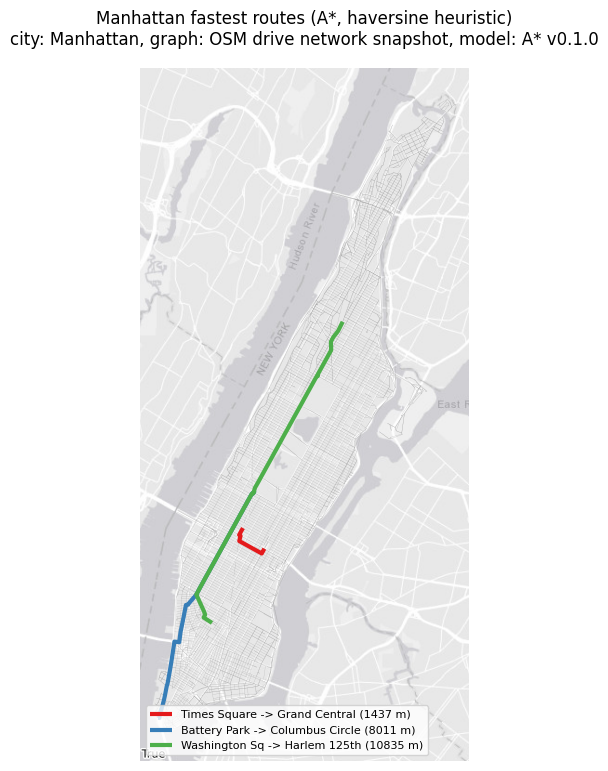

In [6]:
import contextily as ctx

fig, ax = plt.subplots(figsize=(9, 9))
edges = gpd.GeoDataFrame(
    geometry=[
        LineString([(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])])
        for u, v in G.edges()
    ],
    crs="EPSG:4326",
).to_crs(3857)
edges.plot(ax=ax, linewidth=0.2, color="#999999", alpha=0.6)
colors = ["#e41a1c", "#377eb8", "#4daf4a"]
for color, row in zip(colors, rows):
    line = gpd.GeoSeries(
        [LineString([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in row["_a_path"]])], crs="EPSG:4326"
    ).to_crs(3857)
    line.plot(ax=ax, color=color, linewidth=3, label=f"{row['route']} ({row['astar_m']} m)")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, crs=3857, attribution=True)
ax.set_axis_off()
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Manhattan fastest routes (A*, haversine heuristic)\ncity: Manhattan, graph: OSM drive network snapshot, model: A* v0.1.0")
fig.savefig(FIG_DIR / "rt01_routes_manhattan.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Expansion effort

A bar chart of nodes expanded per method makes the heuristic benefit visible.

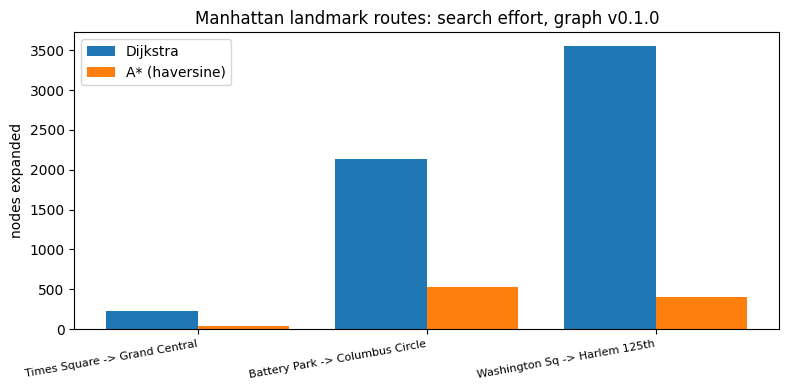

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(summary))
ax.bar(x - 0.2, summary["dijkstra_expanded"], width=0.4, label="Dijkstra")
ax.bar(x + 0.2, summary["astar_expanded"], width=0.4, label="A* (haversine)")
ax.set_xticks(x, summary["route"], rotation=10, ha="right", fontsize=8)
ax.set_ylabel("nodes expanded")
ax.set_title("Manhattan landmark routes: search effort, graph v0.1.0")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rt01_expansions.png", dpi=150)
plt.show()